<a href="https://colab.research.google.com/github/draliaa81-sys/genai-synthetic-data-practice/blob/main/genai_synthetic_data_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install faker --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 24.6 MB/s eta 0:00:00


=== Your Synthetic NZ Customers ===
 CustomerID              Name                       Email  Age     Region AccountType HasLoan
       1001        John Healy        maraea80@example.com   58   Auckland     Savings      No
       1002        Ian Stubbs           mboyd@example.net   33 Wellington      Cheque     Yes
       1003  Lachlan Jellyman catherinebarnes@example.org   61    Dunedin     Savings      No
       1004         Ryan Mann           swebb@example.net   20   Auckland     Savings     Yes
       1005     Connor Hickey      wmacdonald@example.net   32    Dunedin     Savings     Yes
       1006       Sharon Herd   hoarerosemary@example.com   63    Dunedin  Investment     Yes
       1007 Jessica Armstrong     currielynne@example.org   46    Dunedin    Mortgage     Yes
       1008     Raewyn Thomas   nigelanderson@example.com   28   Hamilton    Mortgage      No
       1009        Karen Barr      anikabrown@example.org   27 Wellington    Mortgage     Yes
       1010       Linda 

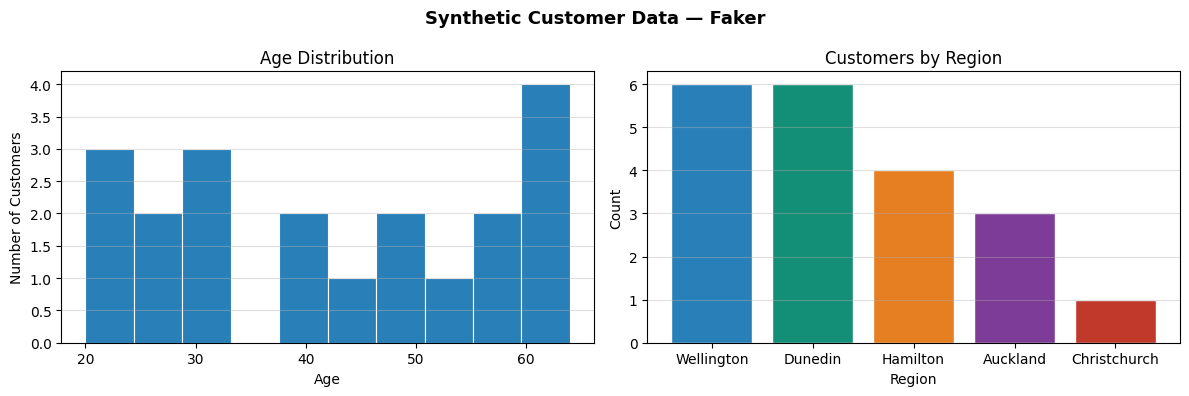

Done! You generated 20 synthetic customer records.


In [11]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from faker import Faker

# ── Step 2: Create our fake data factory ─────────────────────────────

# 'en_NZ' means New Zealand style — NZ names and addresses

fake = Faker('en_NZ')

random.seed(42)   # seed = same results every run, good for learning



# ── Step 3: Decide how many records to generate ──────────────────────

number_of_customers = 20  # change this to 100 or 500 to scale up



# ── Step 4: Build the data — one record per loop ─────────────────────

data = []

for i in range(number_of_customers):

    record = {

        'CustomerID'  : 1001 + i,

        'Name'        : fake.name(),

        'Email'       : fake.email(),

        'Age'         : random.randint(18, 65),

        'Region'      : random.choice(['Auckland','Wellington','Christchurch','Hamilton','Dunedin']),

        'AccountType' : random.choice(['Savings','Cheque','Mortgage','Investment']),

        'HasLoan'     : random.choice(['Yes','No']),

    }

    data.append(record);


# ── Step 5: Put records into a table (DataFrame) ─────────────────────

df = pd.DataFrame(data)



# ── Step 6: Display the first 10 rows ────────────────────────────────

print('=== Your Synthetic NZ Customers ===')

print(df.head(10).to_string(index=False))

print(f'\nTotal records created: {len(df)}')



# ── Step 7: Visualise — two charts side by side ──────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fig.suptitle('Synthetic Customer Data — Faker', fontsize=13, fontweight='bold')



# Chart A: Age distribution (histogram)

axes[0].hist(df['Age'], bins=10, color='#2980B9', edgecolor='white', linewidth=0.8)

axes[0].set_title('Age Distribution')

axes[0].set_xlabel('Age')

axes[0].set_ylabel('Number of Customers')

axes[0].grid(axis='y', alpha=0.4)



# Chart B: Customers by Region (bar chart)

region_counts = df['Region'].value_counts()

colours = ['#2980B9','#148F77','#E67E22','#7D3C98','#C0392B']

axes[1].bar(region_counts.index, region_counts.values, color=colours, edgecolor='white')

axes[1].set_title('Customers by Region')

axes[1].set_xlabel('Region')

axes[1].set_ylabel('Count')

axes[1].grid(axis='y', alpha=0.4)



plt.tight_layout()

plt.show()

print('Done! You generated', len(df), 'synthetic customer records.')

In [9]:
# SDV (Synthetic Data Vault) contains CTGAN and all its dependencies

!pip install sdv==1.28.0 --quiet



# When the green checkmark appears, move to Cell 2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.3/193.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.4/15.4 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.1/75.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.8/206.8 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 8.5 MB/s eta 0:00:00


=== Seed Dataset — first 5 rows ===
 Age  Income_NZD  CreditScore AccountType HasLoan
  56       63799          374     Savings     Yes
  69       32057          712     Savings     Yes
  46      158349          675     Savings      No
  32       55455          719      Cheque     Yes
  60       38044          576      Cheque      No
Seed shape: (200, 5)

Column types detected automatically.

Training CTGAN — watch the progress bar below...


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:168: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(
Gen. (-00.04) | Discrim. (-00.08): 100%|██████████| 100/100 [00:06<00:00, 15.01it/s]



Training complete!

=== Generated Synthetic Data — first 5 rows ===
 Age  Income_NZD  CreditScore AccountType HasLoan
  30     4130220          748     Savings     Yes
  25    12333839          787     Savings      No
  18    14829406          609      Cheque      No
  18    12938700          300     Savings     Yes
  18     7247525          743  Investment      No


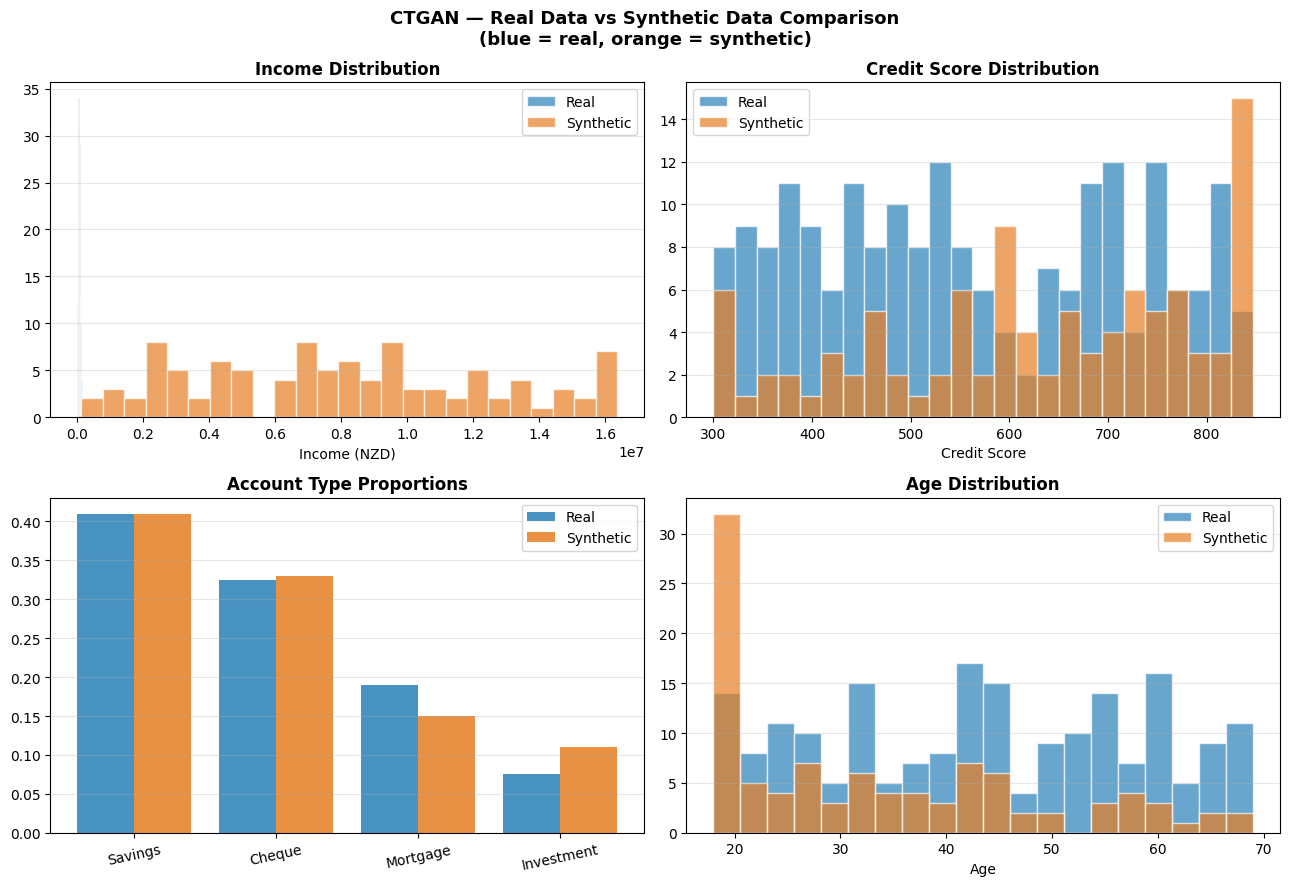

Synthetic data saved to ctgan_output.csv  (100 rows).


In [12]:
# ── Import tools ───────────────────────────────────────────────────

from sdv.single_table import CTGANSynthesizer

from sdv.metadata import SingleTableMetadata

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt



np.random.seed(42)



# ── Step 1: Create a seed dataset ──────────────────────────────────

# In a real project, this would be your actual anonymised data.

# Here we build a small realistic dataset to demonstrate CTGAN.

n = 200

seed_data = pd.DataFrame({

    'Age'         : np.random.randint(18, 70, n),

    'Income_NZD'  : np.random.lognormal(mean=11.0, sigma=0.5, size=n).astype(int),

    'CreditScore' : np.random.randint(300, 850, n),

    'AccountType' : np.random.choice(['Savings','Cheque','Mortgage','Investment'],

                                      n, p=[0.35, 0.30, 0.25, 0.10]),

    'HasLoan'     : np.random.choice(['Yes','No'], n, p=[0.35, 0.65]),

})



print('=== Seed Dataset — first 5 rows ===')

print(seed_data.head().to_string(index=False))

print(f'Seed shape: {seed_data.shape}')



# ── Step 2: Detect column types automatically ──────────────────────

# SDV inspects each column and decides: numeric, categorical, date, etc.

metadata = SingleTableMetadata()

metadata.detect_from_dataframe(seed_data)

print('\nColumn types detected automatically.')



# ── Step 3: Create and train the CTGAN model ──────────────────────

# epochs=100 = the model studies your data 100 times

# verbose=True = shows progress bar so you can see it learning

synthesizer = CTGANSynthesizer(metadata, epochs=100, verbose=True)

print('\nTraining CTGAN — watch the progress bar below...')

synthesizer.fit(seed_data)

print('\nTraining complete!')



# ── Step 4: Generate 100 new synthetic records ────────────────────

synthetic_data = synthesizer.sample(num_rows=100)

print('\n=== Generated Synthetic Data — first 5 rows ===')

print(synthetic_data.head().to_string(index=False))



# ── Step 5: Compare real vs synthetic — 4-panel chart ────────────

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

fig.suptitle('CTGAN — Real Data vs Synthetic Data Comparison\n(blue = real, orange = synthetic)',

             fontsize=13, fontweight='bold')



# Income comparison

axes[0,0].hist(seed_data['Income_NZD'], bins=25, alpha=0.7, color='#2980B9', label='Real', edgecolor='white')

axes[0,0].hist(synthetic_data['Income_NZD'], bins=25, alpha=0.7, color='#E67E22', label='Synthetic', edgecolor='white')

axes[0,0].set_title('Income Distribution', fontweight='bold')

axes[0,0].set_xlabel('Income (NZD)')

axes[0,0].legend()

axes[0,0].grid(axis='y', alpha=0.3)



# Credit score comparison

axes[0,1].hist(seed_data['CreditScore'], bins=25, alpha=0.7, color='#2980B9', label='Real', edgecolor='white')

axes[0,1].hist(synthetic_data['CreditScore'], bins=25, alpha=0.7, color='#E67E22', label='Synthetic', edgecolor='white')

axes[0,1].set_title('Credit Score Distribution', fontweight='bold')

axes[0,1].set_xlabel('Credit Score')

axes[0,1].legend()

axes[0,1].grid(axis='y', alpha=0.3)



# Account type comparison (grouped bar chart)

real_types = seed_data['AccountType'].value_counts(normalize=True)

synt_types = synthetic_data['AccountType'].value_counts(normalize=True)

labels = real_types.index.tolist()

x = np.arange(len(labels))

axes[1,0].bar(x - 0.2, real_types[labels].values, 0.4, label='Real',      color='#2980B9', alpha=0.85)

axes[1,0].bar(x + 0.2, [synt_types.get(l, 0) for l in labels], 0.4, label='Synthetic', color='#E67E22', alpha=0.85)

axes[1,0].set_xticks(x)

axes[1,0].set_xticklabels(labels, rotation=12)

axes[1,0].set_title('Account Type Proportions', fontweight='bold')

axes[1,0].legend()

axes[1,0].grid(axis='y', alpha=0.3)



# Age comparison

axes[1,1].hist(seed_data['Age'], bins=20, alpha=0.7, color='#2980B9', label='Real', edgecolor='white')

axes[1,1].hist(synthetic_data['Age'], bins=20, alpha=0.7, color='#E67E22', label='Synthetic', edgecolor='white')

axes[1,1].set_title('Age Distribution', fontweight='bold')

axes[1,1].set_xlabel('Age')

axes[1,1].legend()

axes[1,1].grid(axis='y', alpha=0.3)



plt.tight_layout()

plt.show()



# ── Step 6: Save to CSV ──────────────────────────────────────────

synthetic_data.to_csv('ctgan_output.csv', index=False)

print(f'Synthetic data saved to ctgan_output.csv  ({len(synthetic_data)} rows).')

=== Synthetic Dataset Summary ===
Label
Normal     500
Anomaly     20
Total records: 520

Average values by label:
         Amount_NZD  Time_Gap_min  Items
Label                                   
Anomaly       482.6         189.5   12.5
Normal         50.1          30.2    3.1


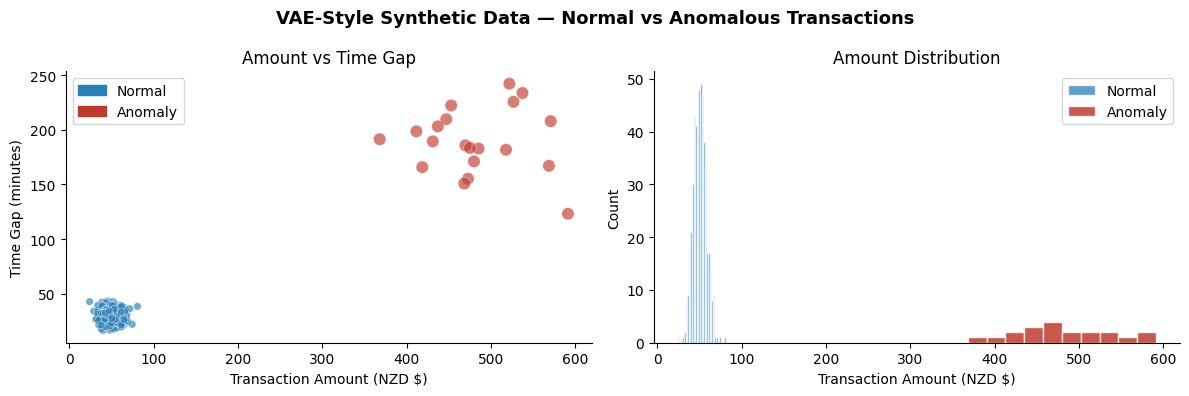


Saved to synthetic_vae_data.csv


In [13]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from matplotlib.patches import Patch



# ── YOUR CONTROLS — change these and re-run ──────────────────────────

n_normal  = 500   # how many normal transactions to generate

n_anomaly = 20    # how many anomalous transactions to generate

np.random.seed(42)



# ── Step 1: Generate NORMAL transactions ──────────────────────────────

# These represent everyday customer behaviour

normal = pd.DataFrame({

    'Amount_NZD'   : np.random.normal(50,  8,  n_normal),  # avg $50 spend

    'Time_Gap_min' : np.random.normal(30,  5,  n_normal),  # ~30 min between txns

    'Items'        : np.random.normal(3,   1,  n_normal).clip(1),

    'Label'        : 'Normal'

})



# ── Step 2: Generate ANOMALOUS transactions ───────────────────────────

# These represent suspicious behaviour (possible fraud)

anomaly = pd.DataFrame({

    'Amount_NZD'   : np.random.normal(480, 60, n_anomaly), # very high spend

    'Time_Gap_min' : np.random.normal(195, 25, n_anomaly), # very long gaps

    'Items'        : np.random.normal(12,  3,  n_anomaly).clip(1),

    'Label'        : 'Anomaly'

})



# ── Step 3: Combine into one dataset ──────────────────────────────────

df = pd.concat([normal, anomaly], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)



print('=== Synthetic Dataset Summary ===')

print(df['Label'].value_counts().to_string())

print(f'Total records: {len(df)}')

print('\nAverage values by label:')

print(df.groupby('Label')[['Amount_NZD','Time_Gap_min','Items']].mean().round(1).to_string())



# ── Step 4: Visualise ─────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fig.suptitle('VAE-Style Synthetic Data — Normal vs Anomalous Transactions',

             fontsize=13, fontweight='bold')



# Chart A: Amount vs Time Gap

colours = df['Label'].map({'Normal':'#2980B9', 'Anomaly':'#C0392B'})

sizes   = df['Label'].map({'Normal':30, 'Anomaly':80})

axes[0].scatter(df['Amount_NZD'], df['Time_Gap_min'],

                c=colours, s=sizes, alpha=0.65, edgecolors='white', linewidth=0.4)

axes[0].set_xlabel('Transaction Amount (NZD $)')

axes[0].set_ylabel('Time Gap (minutes)')

axes[0].set_title('Amount vs Time Gap')

axes[0].legend(handles=[Patch(color='#2980B9', label='Normal'),

                         Patch(color='#C0392B', label='Anomaly')])

axes[0].spines[['top','right']].set_visible(False)



# Chart B: Amount distribution — normal vs anomaly

axes[1].hist(df[df['Label']=='Normal']['Amount_NZD'],

             bins=30, color='#2980B9', alpha=0.75, label='Normal', edgecolor='white')

axes[1].hist(df[df['Label']=='Anomaly']['Amount_NZD'],

             bins=10, color='#C0392B', alpha=0.85, label='Anomaly', edgecolor='white')

axes[1].set_xlabel('Transaction Amount (NZD $)')

axes[1].set_ylabel('Count')

axes[1].set_title('Amount Distribution')

axes[1].legend()

axes[1].spines[['top','right']].set_visible(False)



plt.tight_layout()

plt.show()



# ── Step 5: Save to CSV ───────────────────────────────────────────────

df.to_csv('synthetic_vae_data.csv', index=False)

print('\nSaved to synthetic_vae_data.csv')

In [15]:
# Install the transformers library from Hugging Face
# torch is the deep learning framework GPT-2 runs on
!pip install transformers torch --quiet

# First run downloads GPT-2 (~500MB). Takes 1-2 minutes.
# Subsequent runs use the cached model and are much faster.
# CELL 2 — Generate Synthetic Text for Four Business Scenarios
# ── Import tools ────────────────────────────────────────────────────
from transformers import pipeline
import pandas as pd

# ── Step 1: Load GPT-2 ──────────────────────────────────────────────
print('Loading GPT-2... (first run: ~1-2 min)')
generator = pipeline('text-generation', model='gpt2')
print('Model ready!')

# ── Step 2: Define business-relevant prompts ────────────────────────
# Each prompt is the START of a sentence. GPT-2 will complete it.
prompts = [
    'The customer complained that the product',
    'Our data analytics platform helps businesses',
    'The machine learning model detected a suspicious transaction because',
    'In New Zealand, digital banking adoption has',
]

# ── Step 3: Generation settings ─────────────────────────────────────
# max_new_tokens       = how many new words to add (not counting the prompt)
# num_return_sequences = how many different versions per prompt
# do_sample = True     = adds randomness for varied, creative outputs
# temperature          = 0.5 focused/conservative, 1.2 creative/varied
# pad_token_id         = technical setting to avoid a warning
settings = dict(
    max_new_tokens       = 60,
    num_return_sequences = 2,
    do_sample            = True,
    temperature          = 0.85,
    pad_token_id         = 50256,
)

# ── Step 4: Generate and collect results ────────────────────────────
all_rows = []
for prompt in prompts:
    print(f'\n--- Generating for: "{prompt}" ---')
    outputs = generator(prompt, **settings)
    for j, out in enumerate(outputs, 1):
        text = out['generated_text']
        # Print first 180 chars so the output is not overwhelming
        preview = text[:180] + '...' if len(text) > 180 else text
        print(f'  Version {j}: {preview}')
        all_rows.append({'Prompt': prompt, 'Version': j, 'Generated_Text': text})

# ── Step 5: Save all results ─────────────────────────────────────────
results_df = pd.DataFrame(all_rows)
results_df.to_csv('synthetic_text.csv', index=False)

print(f'\n=== Done ===')
print(f'Total text samples generated: {len(results_df)}')
print(f'Saved to: synthetic_text.csv')

Loading GPT-2... (first run: ~1-2 min)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

... (8 outputs left out)

[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  Version 1: Our data analytics platform helps businesses build an even more integrated and successful approach to their operations.

The Data Analytics Platform provides a new way for enterpri...
  Version 2: Our data analytics platform helps businesses to understand and forecast their business for the coming years.

"If we found our business is at a tipping point in time for the growth...

--- Generating for: "The machine learning model detected a suspicious transaction because" ---


[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  Version 1: The machine learning model detected a suspicious transaction because the transaction was confirmed. The transaction was then sent to the blockchain to be processed.

In the meantim...
  Version 2: The machine learning model detected a suspicious transaction because the transaction was processed on the blockchain. A transaction can be sent from a block of the blockchain to th...

--- Generating for: "In New Zealand, digital banking adoption has" ---
  Version 1: In New Zealand, digital banking adoption has exploded in New Zealand with a whopping 46% uptake so far this year.

There are currently more than 80 new banking accounts in the coun...
  Version 2: In New Zealand, digital banking adoption has increased by 20% in recent years – up from 7% in 2007, and to $2.5 billion in 2014.

New Zealand's digital banking system was introduce...

=== Done ===
Total text samples generated: 8
Saved to: synthetic_text.csv


### Summary Statistics for Generated Synthetic Text

In [16]:
print('DataFrame Info:')
display(results_df.info())

print('\nDescriptive Statistics:')
display(results_df.describe(include='all'))

print('\nNumber of unique prompts:')
display(results_df['Prompt'].nunique())

print('\nNumber of versions per prompt (should be equal to settings.num_return_sequences):')
display(results_df.groupby('Prompt')['Version'].nunique())

# Add a column for text length for further analysis
results_df['Generated_Text_Length'] = results_df['Generated_Text'].apply(len)

print('\nDescriptive statistics for generated text length:')
display(results_df['Generated_Text_Length'].describe())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Prompt          8 non-null      object
 1   Version         8 non-null      int64 
 2   Generated_Text  8 non-null      object
dtypes: int64(1), object(2)
memory usage: 324.0+ bytes


None


Descriptive Statistics:


,Prompt,Version,Generated_Text
count,8,8.000000,8
unique,4,NaN,8
top,The customer complained that the product,NaN,The customer complained that the product was n...
freq,2,NaN,1
mean,NaN,1.500000,NaN
std,NaN,0.534522,NaN
min,NaN,1.000000,NaN
25%,NaN,1.000000,NaN
50%,NaN,1.500000,NaN
75%,NaN,2.000000,NaN



Number of unique prompts:


4


Number of versions per prompt (should be equal to settings.num_return_sequences):


,Version
Prompt,
"In New Zealand, digital banking adoption has",2
Our data analytics platform helps businesses,2
The customer complained that the product,2
The machine learning model detected a suspicious transaction because,2



Descriptive statistics for generated text length:


,Generated_Text_Length
count,8.000000
mean,317.000000
std,107.716559
min,63.000000
25%,321.000000
50%,340.000000
75%,377.750000
max,402.000000


In [17]:
print('\nDescriptive statistics for generated text length:')
display(results_df['Generated_Text_Length'].describe())


Descriptive statistics for generated text length:


,Generated_Text_Length
count,8.000000
mean,317.000000
std,107.716559
min,63.000000
25%,321.000000
50%,340.000000
75%,377.750000
max,402.000000


In [18]:
results_df.to_csv('final_synthetic_text.csv', index=False)
print("DataFrame 'results_df' exported to 'final_synthetic_text.csv'")

DataFrame 'results_df' exported to 'final_synthetic_text.csv'
